# 固定输入/目标幅度下的 (F(g)) 曲线

本 notebook 用于回应审稿人关于“优化参数小误差是否会显著降低保真度”的问题。
对五个代表性构型分别固定表格中的输入猫态幅度 (alpha_{\rm in})、目标猫态幅度
(alpha_{\rm out})、目标压缩参数 (gamma) 和目标奇偶性，只改变 OPA 增益 (g)，计算

$$F(g)=\left|\langle\Psi_{\rm target}|\Psi_{\rm heralded}(g)\rangle\right|^2.$$

图中五条曲线对应：

- 表 II：((m,n)=(1,1))，OCS 输入，(alpha_{\rm in}=1.06)，(alpha_{\rm out}=2.02)，(gamma=0.34)；
- 表 II：((m,n)=(2,2))，OCS 输入，(alpha_{\rm in}=1.06)，(alpha_{\rm out}=1.67)，(gamma=0.31)；
- 表 III：((m,n)=(2,2))，ECS 输入，(alpha_{\rm in}=1.00)，(alpha_{\rm out}=1.71)，(gamma=0.246)，目标奇偶性为 even；
- 表 IV：((m,n)=(1,2))，ECS 输入，(alpha_{\rm in}=1.18)，(alpha_{\rm out}=2.02)，(gamma=0.23)，目标奇偶性为 odd；
- 表 IV：((m,n)=(3,2))，ECS 输入，(alpha_{\rm in}=1.45)，(alpha_{\rm out}=2.00)，(gamma=0.49)，目标奇偶性为 odd。

这是一张“固定目标态”的增益容差图：(gamma) 不随 (g) 重新优化，因此曲线可以直接反映增益偏离表格最优值时的保真度变化。

## 模型卡

- **信号模式**：单模截断 Fock 空间，维数 `N_DIM=50`。
- **输入态**：归一化薛定谔猫态，实幅度 (alpha_{\rm in})，奇偶性由表格行指定。
- **条件操作**：OPA 闲频输入 (|m\rangle)，闲频输出后选择 (|n\rangle)，使用论文式 (3)-(4)。
- **目标态**：论文式 (18) 的压缩猫态，固定表格中的 (alpha_{\rm out})、(gamma) 和目标 parity。
- **扫描变量**：(gin[1.01,3.00])，步长 0.01；每个构型的 `g_opt` 仅用于标记参考位置。取 g>1 是因为 g=1 时无 OPA 相互作用，部分 (m,n) 条件事件的输出态范数为零。
- **数值类型**：确定性计算；不包含随机采样。


In [2]:
# 1. 依赖与计算设置
from __future__ import annotations

import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
})

N_DIM = 50                 # Fock 截断维数（影响计算精度）
G_MIN, G_MAX, G_STEP = 1.01, 3.00, 0.01  # 扫描 g 的范围和步长


In [3]:
# 2. 论文数据（只在这里修改物理参数）
# 参数直接来自论文表 II、表 III 和表 IV；不要在绘图单元中重复修改。
# (3,2) 选择 Table IV 的 ECS 行；该行目标输出 parity 为 odd。
CONFIGURATIONS = {
    "(1,1) OCS (Table II)": {
        "m": 1, "n": 1, "g_opt": 1.60,
        "alpha_in": 1.06, "alpha_out": 2.02, "gamma": 0.34,
        "input_parity": "odd", "target_parity": "odd",
        "table_fidelity": 0.992,
    },
    "(2,2) OCS (Table II)": {
        "m": 2, "n": 2, "g_opt": 1.36,
        "alpha_in": 1.06, "alpha_out": 1.67, "gamma": 0.31,
        "input_parity": "odd", "target_parity": "odd",
        "table_fidelity": 0.999,
    },
    "(2,2) ECS (Table III, alpha_in=1.00)": {
        "m": 2, "n": 2, "g_opt": 2.80,
        "alpha_in": 1.00, "alpha_out": 1.71, "gamma": 0.246,
        "input_parity": "even", "target_parity": "even",
        "table_fidelity": 0.999,
    },
    "(1,2) ECS (Table IV)": {
        "m": 1, "n": 2, "g_opt": 1.05,
        "alpha_in": 1.18, "alpha_out": 2.02, "gamma": 0.23,
        "input_parity": "even", "target_parity": "odd",
        "table_fidelity": 0.996,
    },
    "(3,2) ECS (Table IV)": {
        "m": 3, "n": 2, "g_opt": 1.60,
        "alpha_in": 1.45, "alpha_out": 2.00, "gamma": 0.49,
        "input_parity": "even", "target_parity": "odd",
        "table_fidelity": 0.996,
    },
}


## 3. 态与保真度模型

以下代码只负责实现论文式 (3)-(4)、(6) 和 (18)，不包含论文参数或绘图设置。

In [4]:
# 3. 论文式 (3)-(4)、(6)、(18) 的实现
def cat_state(dim: int, alpha: float, parity: str) -> qt.Qobj:
    sign = -1.0 if parity == "odd" else 1.0
    return (qt.coherent(dim, alpha) + sign * qt.coherent(dim, -alpha)).unit()


def attenuate_fock_amplitudes(state: qt.Qobj, gain: float) -> qt.Qobj:
    amplitudes = state.full().ravel()
    return qt.Qobj(
        (amplitudes * gain ** (-np.arange(len(amplitudes)))).reshape((-1, 1)),
        dims=state.dims,
    )


def h_coefficient(k: int, m: int, n: int, gain: float) -> float:
    added = n - m + k
    if added < 0:
        return 0.0
    G = math.sqrt(gain * gain - 1.0) / gain
    numerator = ((-1) ** added) * G ** (n - m + 2 * k)
    numerator *= math.sqrt(math.factorial(n) * math.factorial(m))
    denominator = gain ** (m - k + 1)
    denominator *= math.factorial(k) * math.factorial(added) * math.factorial(m - k)
    return numerator / denominator


def opa_heralded_state(signal: qt.Qobj, m: int, n: int, gain: float) -> qt.Qobj:
    if gain < 1.0:
        raise ValueError("OPA gain must satisfy g >= 1.")
    dim = signal.shape[0]
    a = qt.destroy(dim)
    output = 0 * signal
    for k in range(m + 1):
        added = n - m + k
        coefficient = h_coefficient(k, m, n, gain)
        if coefficient:
            output += coefficient * (a.dag() ** added) * attenuate_fock_amplitudes((a ** k) * signal, gain)
    return output


def squeezed_cat_target(dim: int, alpha_out: float, gamma: float, parity: str) -> qt.Qobj:
    return (qt.squeeze(dim, gamma) * cat_state(dim, alpha_out, parity)).unit()


def fidelity(output: qt.Qobj, target: qt.Qobj) -> float:
    return float(abs(target.overlap(output.unit())) ** 2)


In [5]:
# 4. 固定论文数据，只扫描 g
g_values = np.arange(G_MIN, G_MAX + 0.5 * G_STEP, G_STEP)
scan_results = {}

for label, cfg in CONFIGURATIONS.items():
    signal = cat_state(N_DIM, cfg["alpha_in"], cfg["input_parity"])
    target = squeezed_cat_target(N_DIM, cfg["alpha_out"], cfg["gamma"], cfg["target_parity"])
    f_values = []
    for gain in g_values:
        heralded = opa_heralded_state(signal, cfg["m"], cfg["n"], float(gain))
        # Zero norm means the selected heralding event has zero probability.
        f_values.append(np.nan if heralded.norm() < 1e-14 else fidelity(heralded, target))
    f_values = np.asarray(f_values, dtype=float)
    scan_results[label] = {"g": g_values.copy(), "fidelity": f_values, "target": target}
    i_opt = int(np.argmin(abs(g_values - cfg["g_opt"])))
    print(
        f"{label}: table g_opt={cfg['g_opt']:.2f}, "
        f"F(g_opt)={f_values[i_opt]:.6f}, table F={cfg['table_fidelity']:.3f}"
    )

np.savetxt(
    "fidelity_vs_g_four_configurations.csv",
    np.column_stack([g_values] + [scan_results[label]["fidelity"] for label in CONFIGURATIONS]),
    delimiter=",",
    header="g," + ",".join(label.replace(",", "_") for label in CONFIGURATIONS),
    comments="",
)


(1,1) OCS (Table II): table g_opt=1.60, F(g_opt)=0.992161, table F=0.992
(2,2) OCS (Table II): table g_opt=1.36, F(g_opt)=0.999331, table F=0.999
(2,2) ECS (Table III, alpha_in=1.00): table g_opt=2.80, F(g_opt)=0.999081, table F=0.999
(1,2) ECS (Table IV): table g_opt=1.05, F(g_opt)=0.996026, table F=0.996
(3,2) ECS (Table IV): table g_opt=1.60, F(g_opt)=0.995720, table F=0.996


In [32]:
# 5. 绘图设置（只在这里修改图像外观）
FIG_SIZE = (10.5, 6.5)
FIG_DPI = 160
SAVE_DPI = 300
LINE_WIDTH = 2.2
MARKER_SIZE = 42
AXIS_LABEL_SIZE = 20
Y_LABEL_SIZE = 20
TITLE_SIZE = 20
LEGEND_SIZE = 17
LEGEND_LOCATION = "lower right"
X_LIMITS = (G_MIN, G_MAX)
Y_LIMITS = (0.0, 1.005)
GRID_ALPHA = 0.25
CURVE_COLORS = ["#0072B2", "#D55E00", "#009E73", "#332288", "#CC79A7"]
CURVE_MARKERS = ["o", "s", "^", "P", "D"]
CURVE_LINESTYLES = ["-", "--", "-.", (0, (3, 1, 1, 1)), ":"]
CURVE_MARK_EVERY = 12
THRESHOLD_LINES = ((0.99, "#009E73", "--"), (0.95, "#E69F00", "-."))


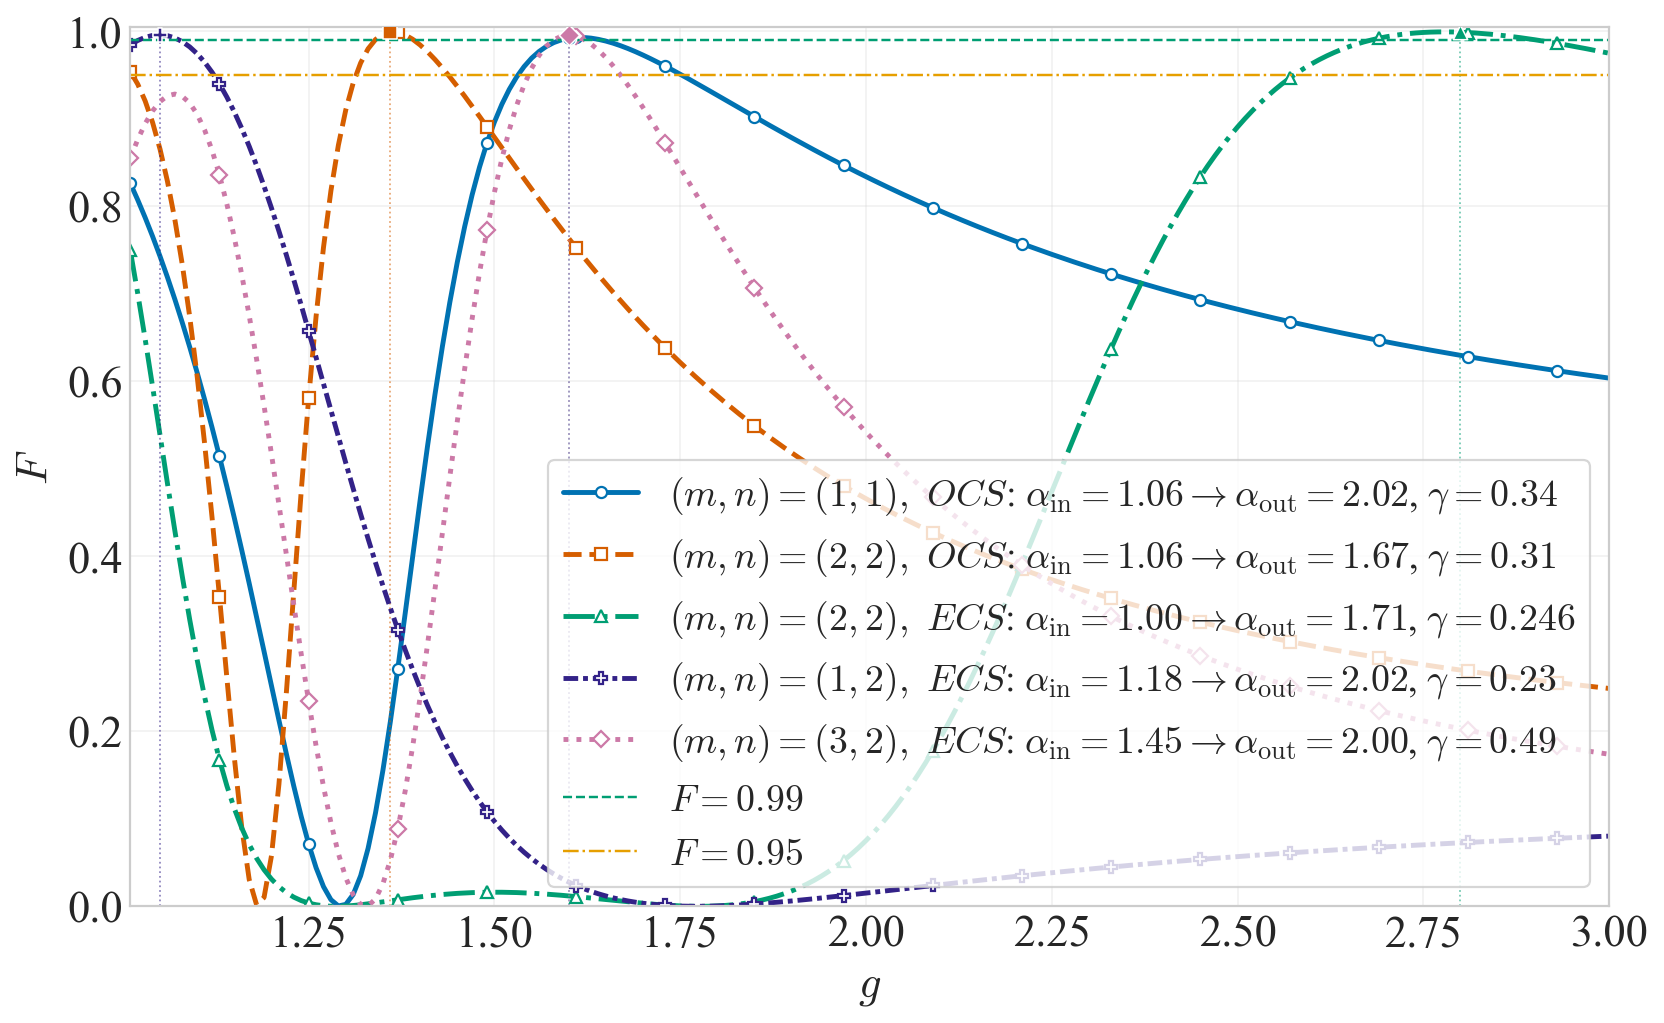

In [33]:
# 6. 绘制五种构型的 F(g) 曲线
fig, ax = plt.subplots(figsize=FIG_SIZE, dpi=FIG_DPI)

for (label, cfg), curve_color, curve_marker, curve_linestyle in zip(
    CONFIGURATIONS.items(), CURVE_COLORS, CURVE_MARKERS, CURVE_LINESTYLES
):
    values = scan_results[label]["fidelity"]
    parity_text = {"odd": "OCS", "even": "ECS"}[cfg["input_parity"]]
    ax.plot(
        g_values, values, lw=LINE_WIDTH, color=curve_color, ls=curve_linestyle,
        marker=curve_marker, markevery=CURVE_MARK_EVERY, ms=5,
        markerfacecolor="white", markeredgecolor=curve_color, markeredgewidth=1.0,
        label=(
            rf"$(m,n)=({cfg['m']},{cfg['n']}),\ {parity_text}$: "
            rf"$\alpha_{{\rm in}}={cfg['alpha_in']:.2f}\to\alpha_{{\rm out}}={cfg['alpha_out']:.2f}$, "
            rf"$\gamma={cfg['gamma']:g}$"
        ),
    )
    i_opt = int(np.argmin(abs(g_values - cfg["g_opt"])))
    ax.scatter(
        [g_values[i_opt]], [values[i_opt]], color=curve_color, marker=curve_marker, s=MARKER_SIZE,
        edgecolor="white", linewidth=0.7, zorder=5,
    )
    ax.axvline(cfg["g_opt"], color=curve_color, ls=":", lw=0.8, alpha=0.55)

for threshold, color, style in THRESHOLD_LINES:
    ax.axhline(threshold, color=color, ls=style, lw=1.1, label=rf"$F={threshold:.2f}$")

ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)
ax.tick_params(axis="both", labelsize=20)
ax.set_xlabel(r"$g$", fontsize=AXIS_LABEL_SIZE)
ax.set_ylabel(r"$F$", fontsize=Y_LABEL_SIZE)
ax.legend(loc=LEGEND_LOCATION, fontsize=LEGEND_SIZE, frameon=True)
ax.grid(True, alpha=GRID_ALPHA)
fig.tight_layout()
fig.savefig("fidelity_vs_g_four_configurations.png", dpi=SAVE_DPI, bbox_inches="tight")
plt.show()


In [34]:
# 7. 输出各构型的高保真增益容差区间
def interval_for_threshold(values: np.ndarray, threshold: float):
    mask = values >= threshold
    if not np.any(mask):
        return None
    return float(g_values[mask][0]), float(g_values[mask][-1])


print("\\nFixed-target gain tolerance intervals")
for label, cfg in CONFIGURATIONS.items():
    values = scan_results[label]["fidelity"]
    print(f"\\n{label}, table g_opt={cfg['g_opt']:.2f}")
    for threshold in (0.99, 0.95, 0.90):
        interval = interval_for_threshold(values, threshold)
        if interval is None:
            print(f"  F >= {threshold:.2f}: no interval in scan range")
        else:
            relative_width = (interval[1] - interval[0]) / cfg["g_opt"]
            print(f"  F >= {threshold:.2f}: g in {interval}, relative width={relative_width:.2%}")


\nFixed-target gain tolerance intervals
\n(1,1) OCS (Table II), table g_opt=1.60
  F >= 0.99: g in (1.5900000000000005, 1.6400000000000006), relative width=3.13%
  F >= 0.95: g in (1.5400000000000005, 1.7500000000000007), relative width=13.13%
  F >= 0.90: g in (1.5100000000000005, 1.8500000000000008), relative width=21.25%
\n(2,2) OCS (Table II), table g_opt=1.36
  F >= 0.99: g in (1.3400000000000003, 1.3900000000000003), relative width=3.68%
  F >= 0.95: g in (1.01, 1.4300000000000004), relative width=30.88%
  F >= 0.90: g in (1.01, 1.4800000000000004), relative width=34.56%
\n(2,2) ECS (Table III, alpha_in=1.00), table g_opt=2.80
  F >= 0.99: g in (2.6800000000000015, 2.9000000000000017), relative width=7.86%
  F >= 0.95: g in (2.5800000000000014, 3.0000000000000018), relative width=15.00%
  F >= 0.90: g in (2.5100000000000016, 3.0000000000000018), relative width=17.50%
\n(1,2) ECS (Table IV), table g_opt=1.05
  F >= 0.99: g in (1.03, 1.07), relative width=3.81%
  F >= 0.95: g in (1

## 如何解释这张图

这里固定了每个表格行的整个目标态，只改变 (g)。因此曲线可以用来回答：

> 如果实验增益偏离表格中的 (g_{\rm opt})，但仍希望生成同一个固定的目标猫态，保真度会怎样变化？

五条曲线不能直接比较绝对高度所代表的“谁一定更好”，因为五种构型的输入态、目标幅度和目标压缩参数不同；它们主要用于比较各自对 (g) 偏差的容忍范围。每条曲线同时使用独立颜色、线型和重复标记以便区分。表格中的 (F) 是优化点的参考值，图中最优点标记是使用公开的四舍五入参数重新计算得到的值。

如果需要画“每个 (g) 都重新优化 (gamma)”的可重新标定曲线，把扫描单元中的固定 `target` 改成对每个 (g) 优化 (gamma)。但那张图反映的是重新调参后的最佳可达保真度，不是严格的增益漂移容差。

### 修改位置

- 修改论文参数：第 2 个代码单元“论文数据”；
- 修改扫描范围和步长：第 1 个代码单元“计算设置”；
- 修改画布、字号、线宽、颜色、图例位置和坐标范围：第 5 个代码单元“绘图设置”。